# Этап 1. Знакомство с данными и EDA (разведочный анализ данных)

## Цель работы

Изучить структуру датасета Goodbooks-10k, провести разведочный анализ данных
и выявить особенности, которые могут повлиять на качество рекомендательных моделей.

В рамках этапа необходимо:

1. Загрузить исходные данные.
2. Изучить структуру таблиц, типы данных, пропуски и дубликаты.
3. Проанализировать распределение пользовательских оценок.
4. Исследовать активность пользователей и популярность книг.
5. Определить наиболее распространенные теги.
6. Выявить основные проблемы данных (разреженность, смещение популярности и холодный старт).

## 1.1. Загрузка исходных данных

Для анализа используется датасет Goodbooks-10k,
содержащий оценки пользователей, информацию о книгах
и пользовательские теги.

Исходные данные представлены следующими таблицами:

- `ratings.csv` -> оценки книг пользователями.
- `books.csv` -> метаданные книг.
- `tags.csv` -> справочник тегов.
- `book_tags.csv` -> связи книг с тегами.
- `to_read.csv` -> книги, отмеченные пользователями для последующего чтения.

Основной анализ будет выполнен по первым четырем таблицам, согласно условию задания.
Таблица `to_read.csv` рассматривается как дополнительный источник неявной обратной связи.

### Импорты

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from homework_tasks.recommendation_systems.homework_goodbooks.src.data_loader import (
    load_raw_data,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

### Загрузка данных

In [2]:
raw_data = load_raw_data()

ratings = raw_data["ratings"]
books = raw_data["books"]
tags = raw_data["tags"]
book_tags = raw_data["book_tags"]
to_read = raw_data["to_read"]

for name, dataframe in raw_data.items():
    print(f"{name}: {dataframe.shape}")

ratings: (981756, 3)
books: (10000, 23)
tags: (34252, 2)
book_tags: (999912, 3)
to_read: (912705, 2)


## 1.2. Первичное исследование структуры данных

На данном этапе проверим:

- количество строк и столбцов в каждой таблице
- названия и типы признаков
- наличие пропущенных значений
- наличие полных дубликатов и повторяющихся идентификаторов

Это позволит определить необходимые действия по подготовке данных
перед построением рекомендательных моделей.

### Структура таблиц

In [3]:

for name, dataframe in raw_data.items():
    print(f"\nТаблица: {name}")
    print(f"Размер: {dataframe.shape}")
    print("\nТипы данных:")
    dataframe.info()


Таблица: ratings
Размер: (981756, 3)

Типы данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 981756 entries, 0 to 981755
Data columns (total 3 columns):
 #   Column   Non-Null Count   Dtype
---  ------   --------------   -----
 0   book_id  981756 non-null  int64
 1   user_id  981756 non-null  int64
 2   rating   981756 non-null  int64
dtypes: int64(3)
memory usage: 22.5 MB

Таблица: books
Размер: (10000, 23)

Типы данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         10000 non-null  int64  
 1   book_id                    10000 non-null  int64  
 2   best_book_id               10000 non-null  int64  
 3   work_id                    10000 non-null  int64  
 4   books_count                10000 non-null  int64  
 5   isbn                       9300 non-null   object 
 6   isb

### Первые строки

In [4]:
display(ratings.head())
display(books.head())
display(tags.head())
display(book_tags.head())
display(to_read.head())

,book_id,user_id,rating
0,1,314,5
1,1,439,3
2,1,588,5
3,1,1169,4
4,1,1185,4


,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,title,language_code,average_rating,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,"The Hunger Games (The Hunger Games, #1)",eng,4.34,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,Harry Potter and the Sorcerer's Stone (Harry P...,eng,4.44,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,"Twilight (Twilight, #1)",en-US,3.57,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,To Kill a Mockingbird,eng,4.25,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,The Great Gatsby,eng,3.89,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-
3,3,--12-
4,4,--122-


,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173
3,1,8717,12986
4,1,33114,12716


,user_id,book_id
0,1,112
1,1,235
2,1,533
3,1,1198
4,1,1874


### Проверка пропущенных значений

Проверим наличие пропусков в исходных таблицах и рассчитаем их долю в процентах.

Пропущенные значения могут влиять на качество рекомендаций,
особенно если отсутствуют названия книг или другие признаки, необходимые для контентной модели.

In [5]:
for name, dataframe in raw_data.items():
    missing_count = dataframe.isna().sum()
    missing_percent = dataframe.isna().mean() * 100

    missing_stats = pd.DataFrame(
        {
            "Количество пропусков": missing_count,
            "Доля пропусков, %": missing_percent.round(2),
        }
    )

    # Показываем только столбцы с пропущенными значениями
    missing_stats = missing_stats[
        missing_stats["Количество пропусков"] > 0
        ].sort_values("Доля пропусков, %", ascending=False)

    print(f"\nТаблица: {name}")

    if missing_stats.empty:
        print("Пропущенные значения отсутствуют.")
    else:
        display(missing_stats)



Таблица: ratings
Пропущенные значения отсутствуют.

Таблица: books


,Количество пропусков,"Доля пропусков, %"
language_code,1084,10.84
isbn,700,7.00
isbn13,585,5.85
original_title,585,5.85
original_publication_year,21,0.21



Таблица: tags
Пропущенные значения отсутствуют.

Таблица: book_tags
Пропущенные значения отсутствуют.

Таблица: to_read
Пропущенные значения отсутствуют.


### Проверка дубликатов

Проверим наличие полностью повторяющихся строк в исходных таблицах.

Дополнительно исследуем уникальность идентификаторов
и повторяющиеся пары `(user_id, book_id)` в таблице `ratings`.

Повторяющиеся оценки одного пользователя для одной книги
могут влиять на построение матрицы взаимодействий
и обучение рекомендательных моделей.

In [6]:
# === Полные дубликаты ===

duplicates_stats = []

for name, dataframe in raw_data.items():
    duplicates_count = dataframe.duplicated().sum()

    duplicates_stats.append(
        {
            "Таблица": name,
            "Количество дубликатов": duplicates_count,
            "Доля дубликатов, %": round(
                duplicates_count / len(dataframe) * 100, 2
            ),
        }
    )

duplicates_df = pd.DataFrame(duplicates_stats)

display(duplicates_df)

,Таблица,Количество дубликатов,"Доля дубликатов, %"
0,ratings,1644,0.17
1,books,0,0.00
2,tags,0,0.00
3,book_tags,6,0.00
4,to_read,0,0.00


In [7]:
# === Повторяющиеся идентификаторы ===

# Проверяем уникальность первичных идентификаторов
# и составных ключей
key_columns = {
    "ratings": ["user_id", "book_id"],
    "books": ["id"],
    "tags": ["tag_id"],
    "book_tags": ["goodreads_book_id", "tag_id"],
    "to_read": ["user_id", "book_id"],
}

for name, columns in key_columns.items():
    dataframe = raw_data[name]

    duplicates_count = dataframe.duplicated(subset=columns).sum()

    print(
        f"{name}: повторяющихся записей по {columns} - {duplicates_count}"
    )

ratings: повторяющихся записей по ['user_id', 'book_id'] - 2278
books: повторяющихся записей по ['id'] - 0
tags: повторяющихся записей по ['tag_id'] - 0
book_tags: повторяющихся записей по ['goodreads_book_id', 'tag_id'] - 8
to_read: повторяющихся записей по ['user_id', 'book_id'] - 0


In [8]:
# === Повторяющиеся оценки ===

# Выделяем все записи с повторяющимися парами "пользователь - книга"
duplicate_ratings = ratings[
    ratings.duplicated(subset=["user_id", "book_id"], keep=False)
].sort_values(["user_id", "book_id"])

print(f"Количество записей с повторяющимися оценками: {len(duplicate_ratings)}")
print(
    "Количество уникальных пар с повторениями:",
    duplicate_ratings[["user_id", "book_id"]].drop_duplicates().shape[0],
)

display(duplicate_ratings.head(10))

Количество записей с повторяющимися оценками: 4487
Количество уникальных пар с повторениями: 2209


,book_id,user_id,rating
459828,4608,7,3
459829,4608,7,2
883645,8946,16,5
883646,8946,16,3
702002,7063,17,5
702003,7063,17,5
613364,6160,25,3
613365,6160,25,4
883648,8946,25,5
883649,8946,25,5


### Выводы по первичной проверке качества данных

По результатам исследования исходных таблиц выявлены следующие особенности:

1. Пропущенные значения присутствуют только в `books.csv`.
Наибольшая доля пропусков наблюдается в
`language_code` (10,84%), `isbn` (7%) и `original_title` (5,85%).

2. В таблице `ratings.csv` обнаружено 1 644 полных дубликата и 2 278 повторяющихся записей
по ключу `(user_id, book_id)`. Некоторые повторяющиеся оценки различаются,
поэтому перед обучением моделей потребуется их агрегировать.

3. В `book_tags.csv` обнаружено 8 повторяющихся записей по составному ключу `(goodreads_book_id, tag_id)`.
При подготовке контентных признаков потребуется устранить эти повторения.

4. В остальных таблицах повторяющихся записей по проверенным ключам не обнаружено.

5. При объединении таблиц необходимо учитывать различие идентификаторов книг:
`ratings.book_id` соответствует `books.id`,
а `book_tags.goodreads_book_id` соответствует `books.book_id`.

**Итог:**

Исходные данные пригодны для построения рекомендательных моделей,
однако перед обучением потребуется обработка повторяющихся взаимодействий
и отдельных пропущенных значений.

На этапе EDA исходные данные оставляем без изменений.

## 1.3. Распределение пользовательских оценок

Исследуем распределение оценок в таблице `ratings.csv`.

Необходимо определить:

- сколько оценок приходится на каждое значение от 1 до 5
- какие оценки встречаются чаще всего
- среднее и медианное значение рейтинга
- существует ли смещение в сторону высоких оценок

На данном этапе используем исходные данные.
Повторяющиеся оценки будут обработаны позднее при подготовке обучающей выборки.

In [9]:
# === Количество и доля оценок каждого значения ===

rating_counts = ratings["rating"].value_counts().sort_index()
rating_percent = ratings["rating"].value_counts(
    normalize=True
).sort_index() * 100

rating_stats = pd.DataFrame(
    {
        "Количество оценок": rating_counts,
        "Доля оценок, %": rating_percent.round(2),
    }
)

display(rating_stats)

print(f"Средняя оценка: {ratings['rating'].mean():.2f}")
print(f"Медианная оценка: {ratings['rating'].median():.2f}")
print(f"Наиболее частая оценка: {ratings['rating'].mode().iloc[0]}")

,Количество оценок,"Доля оценок, %"
rating,,
1,19575,1.99
2,63231,6.44
3,248623,25.32
4,357366,36.40
5,292961,29.84


Средняя оценка: 3.86
Медианная оценка: 4.00
Наиболее частая оценка: 4


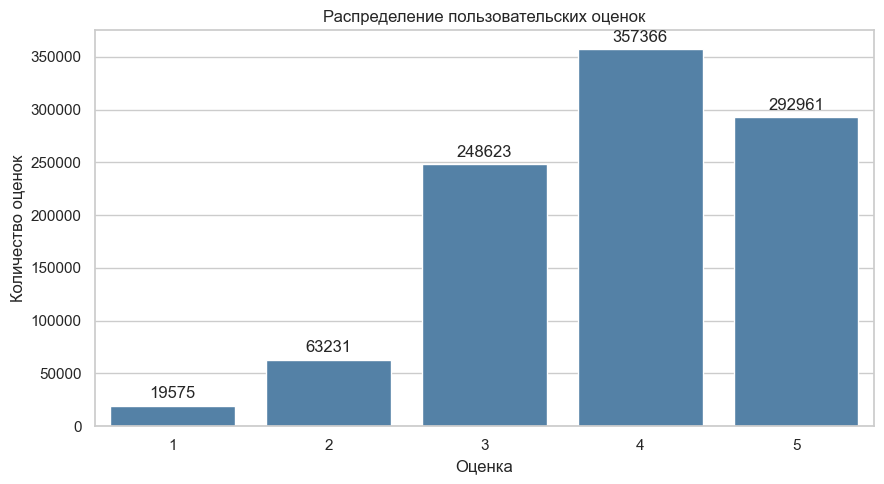

In [10]:
# === Визуализация распределения ===

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    color="steelblue",
)

# Показываем количество оценок над каждым столбцом
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.title("Распределение пользовательских оценок")
plt.xlabel("Оценка")
plt.ylabel("Количество оценок")
plt.tight_layout()
plt.show()


In [11]:
# === Доля положительных оценок ===

from homework_tasks.recommendation_systems.homework_goodbooks.src.config import (
    RELEVANCE_THRESHOLD,
)

# Положительными считаем оценки не ниже установленного порога
positive_ratings = ratings["rating"] >= RELEVANCE_THRESHOLD

positive_count = positive_ratings.sum()
positive_percent = positive_ratings.mean() * 100

print(f"Порог положительной оценки: {RELEVANCE_THRESHOLD}")
print(f"Количество положительных оценок: {positive_count}")
print(f"Доля положительных оценок: {positive_percent:.2f}%")

Порог положительной оценки: 4
Количество положительных оценок: 650327
Доля положительных оценок: 66.24%


### Выводы по распределению оценок

По результатам анализа распределения пользовательских оценок установлено:

1. Наиболее распространенной является оценка 4 - 36,40% всех записей.
На втором месте оценка 5 - 29,84%.

2. Средняя оценка составляет 3,86, медианная - 4.
Это указывает на преобладание относительно высоких рейтингов.

3. Положительные оценки (4 и 5) составляют 66,24% всех взаимодействий.
Низкие оценки (1 и 2) встречаются значительно реже - около 8,43%.

4. Распределение оценок смещено в сторону высоких значений.
Такое смещение необходимо учитывать при построении рекомендательных моделей,
поскольку высокий средний рейтинг не всегда позволяет уверенно выделить
наиболее предпочтительные книги.

**Итог:**

В датасете наблюдается преобладание положительных оценок.
Для последующей оценки качества рекомендаций будем считать
релевантными книги с рейтингом не ниже 4.

## 1.4. Анализ активности пользователей

Исследуем, насколько активно пользователи оценивают книги.

Для этого необходимо:

- рассчитать количество оценок каждого пользователя
- изучить распределение пользовательской активности
- выявить наиболее активных и малоактивных пользователей
- определить долю пользователей с небольшим количеством взаимодействий

Результаты помогут оценить проблему холодного старта пользователей и понять,
насколько полно представлены их предпочтения в данных.

In [12]:
# === Количество оценок на пользователя ===

user_activity = ratings.groupby("user_id").size()

print(f"Количество пользователей: {len(user_activity)}")
print(f"Всего оценок: {len(ratings)}")
print(f"Среднее количество оценок: {user_activity.mean():.2f}")
print(f"Медианное количество оценок: {user_activity.median():.2f}")
print(f"Минимальное количество оценок: {user_activity.min()}")
print(f"Максимальное количество оценок: {user_activity.max()}")

# Основные статистики распределения активности пользователей
display(
    user_activity.describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

Количество пользователей: 53424
Всего оценок: 981756
Среднее количество оценок: 18.38
Медианное количество оценок: 8.00
Минимальное количество оценок: 2
Максимальное количество оценок: 200


count    53424.000000
mean        18.376685
std         26.268690
min          2.000000
25%          3.000000
50%          8.000000
75%         22.000000
90%         47.000000
95%         71.000000
99%        134.000000
max        200.000000
dtype: float64

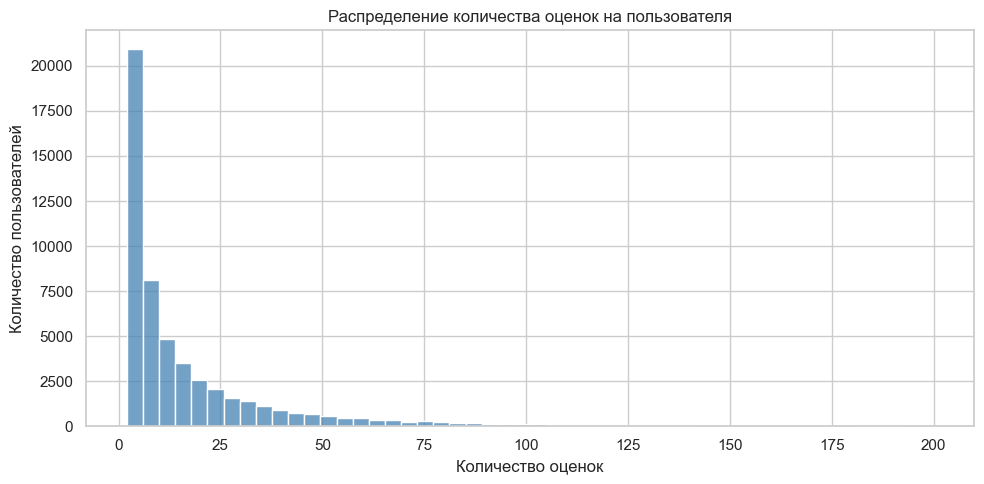

In [13]:
# === Распределение количества оценок на пользователя ===

plt.figure(figsize=(10, 5))

sns.histplot(
    user_activity,
    bins=50,
    color="steelblue",
)

plt.title("Распределение количества оценок на пользователя")
plt.xlabel("Количество оценок")
plt.ylabel("Количество пользователей")
plt.tight_layout()
plt.show()

In [14]:
# === Топ-10 наиболее активных пользователей ===

top_active_users = (
    user_activity.sort_values(ascending=False)
    .head(10)
    .reset_index(name="Количество оценок")
)

display(top_active_users)

,user_id,Количество оценок
0,12874,200
1,30944,200
2,52036,199
3,12381,199
4,28158,199
5,6630,197
6,45554,197
7,37834,197
8,24143,196
9,9668,196


In [15]:
# === Анализ пользователей с небольшим количеством взаимодействий ===

activity_thresholds = [2, 5, 10, 20]

low_activity_stats = []

for threshold in activity_thresholds:
    users_count = (user_activity <= threshold).sum()

    low_activity_stats.append(
        {
            "Количество оценок не более": threshold,
            "Количество пользователей": users_count,
            "Доля пользователей, %": round(
                users_count / len(user_activity) * 100, 2
            ),
        }
    )

low_activity_df = pd.DataFrame(low_activity_stats)

display(low_activity_df)

,Количество оценок не более,Количество пользователей,"Доля пользователей, %"
0,2,8302,15.54
1,5,20926,39.17
2,10,30414,56.93
3,20,39417,73.78


### Выводы по активности пользователей

По результатам анализа активности пользователей установлено:

1. В датасете представлено 53 424 пользователя, которые оставили 981 756 оценок.
Среднее количество оценок на пользователя составляет 18,38, медианное - 8.

2. Распределение пользовательской активности неравномерно.
Большинство пользователей оставили относительно небольшое количество оценок,
тогда как отдельные пользователи имеют до 200 взаимодействий.

3. Более половины пользователей (56,93%) оставили не более 10 оценок.
При этом 39,17% пользователей имеют не более 5 оценок.

4. Небольшое количество взаимодействий затрудняет определение индивидуальных предпочтений
и может снижать качество коллаборативной фильтрации.

5. Пользователи без истории оценок в таблице `ratings.csv` отсутствуют,
поэтому непосредственно оценить масштаб строгого холодного старта по этим данным невозможно.

**Итог:**

В датасете наблюдается значительная доля малоактивных пользователей.
При построении рекомендательной системы необходимо учитывать ограниченность пользовательской истории
и предусмотреть альтернативные рекомендации (на основе популярности книг).

## 1.5. Анализ популярности книг

Исследуем популярность книг на основе количества пользовательских оценок.

Для этого необходимо:

- рассчитать количество оценок для каждой книги
- изучить распределение популярности
- определить наиболее популярные книги
- оценить концентрацию взаимодействий среди популярных книг
- проверить наличие эффекта длинного хвоста

Популярность будем определять по количеству оценок, а не по их среднему значению.
Это позволит оценить, насколько часто пользователи взаимодействуют с каждой книгой.

In [16]:
# === Количество оценок на книгу ===

book_popularity = ratings.groupby("book_id").size()

print(f"Количество оцененных книг: {len(book_popularity)}")
print(f"Всего оценок: {len(ratings)}")
print(f"Среднее количество оценок: {book_popularity.mean():.2f}")
print(f"Медианное количество оценок: {book_popularity.median():.2f}")
print(f"Минимальное количество оценок: {book_popularity.min()}")
print(f"Максимальное количество оценок: {book_popularity.max()}")

# Основные статистики распределения популярности книг
display(
    book_popularity.describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

Количество оцененных книг: 10000
Всего оценок: 981756
Среднее количество оценок: 98.18
Медианное количество оценок: 100.00
Минимальное количество оценок: 8
Максимальное количество оценок: 100


count    10000.000000
mean        98.175600
std          5.690167
min          8.000000
25%         99.000000
50%        100.000000
75%        100.000000
90%        100.000000
95%        100.000000
99%        100.000000
max        100.000000
dtype: float64

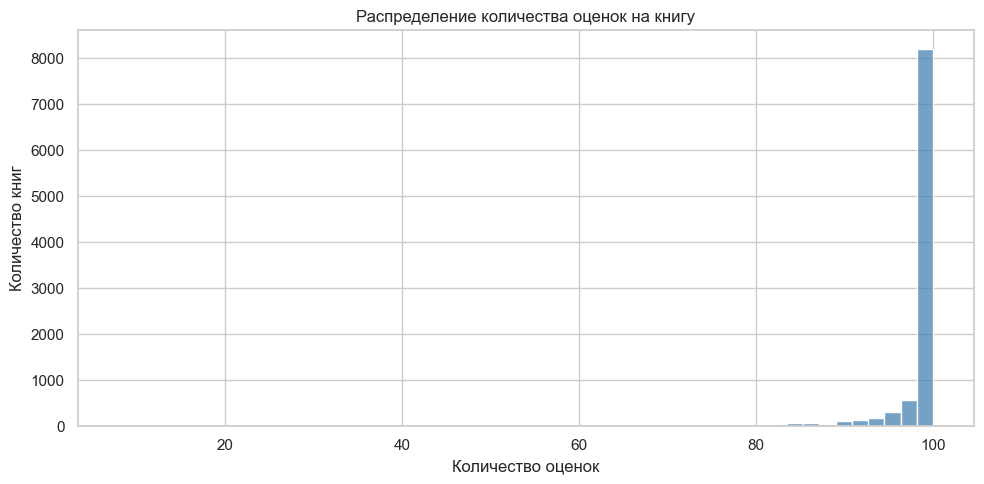

In [17]:
# === Распределение количества оценок на книгу ===

plt.figure(figsize=(10, 5))

sns.histplot(
    book_popularity,
    bins=50,
    color="steelblue",
)

plt.title("Распределение количества оценок на книгу")
plt.xlabel("Количество оценок")
plt.ylabel("Количество книг")
plt.tight_layout()
plt.show()

In [18]:
# === Топ-10 книг по количеству оценок ===

top_popular_books = (
    book_popularity.sort_values(ascending=False)
    .head(10)
    .reset_index(name="Количество оценок")
)

# ratings.book_id соответствует books.id
top_popular_books = top_popular_books.merge(
    books[["id", "title", "authors"]],
    left_on="book_id",
    right_on="id",
    how="left",
)

top_popular_books = top_popular_books[
    ["book_id", "title", "authors", "Количество оценок"]
]

display(top_popular_books)

,book_id,title,authors,Количество оценок
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,100
1,5198,Of Love and Shadows,"Isabel Allende, Margaret Sayers Peden",100
2,5215,Plan B: Further Thoughts on Faith,Anne Lamott,100
3,5214,"The Archer's Tale (The Grail Quest, #1)",Bernard Cornwell,100
4,9803,The Berenstain Bears and Too Much TV,"Stan Berenstain, Jan Berenstain",100
5,5211,Pay It Forward,Catherine Ryan Hyde,100
6,5210,Discipline and Punish: The Birth of the Prison,"Michel Foucault, Alan Sheridan, Thomas Mathies...",100
7,5209,"Odd Apocalypse (Odd Thomas, #5)",Dean Koontz,100
8,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson,100
9,5206,Sick Puppy,Carl Hiaasen,100


In [19]:
# === Доля оценок, приходящихся на наиболее популярные книги ===

popularity_thresholds = [1, 5, 10, 20]

sorted_book_popularity = book_popularity.sort_values(ascending=False)

popularity_stats = []

for threshold in popularity_thresholds:
    # Определяем количество книг в соответствующей верхней доле
    books_count = max(1, int(np.ceil(len(book_popularity) * threshold / 100)))

    # Рассчитываем долю всех оценок, полученную этими книгами
    ratings_count = sorted_book_popularity.head(books_count).sum()

    popularity_stats.append(
        {
            "Доля популярных книг, %": threshold,
            "Количество книг": books_count,
            "Доля всех оценок, %": round(
                ratings_count / len(ratings) * 100, 2
            ),
        }
    )

popularity_df = pd.DataFrame(popularity_stats)

display(popularity_df)

,"Доля популярных книг, %",Количество книг,"Доля всех оценок, %"
0,1,100,1.02
1,5,500,5.09
2,10,1000,10.19
3,20,2000,20.37


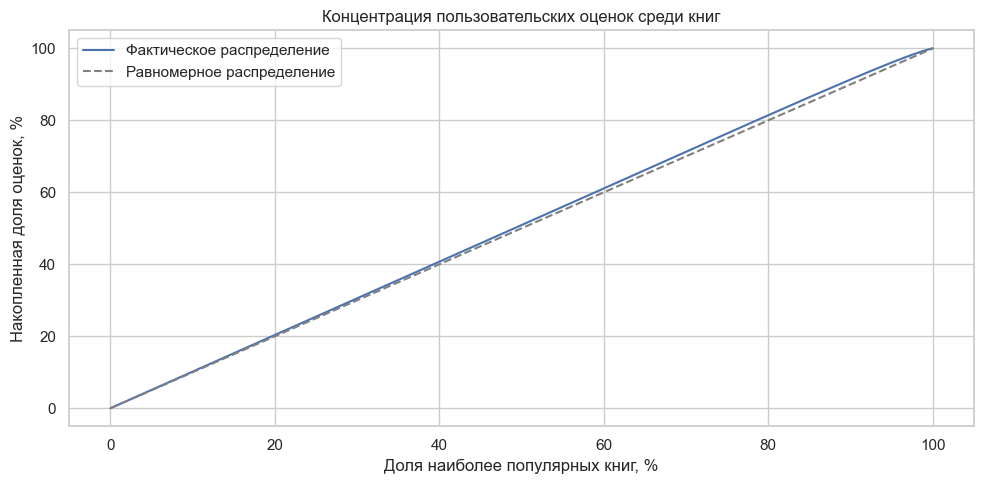

In [20]:
# === Накопленная доля оценок по популярности книг ===

cumulative_ratings = sorted_book_popularity.cumsum() / len(ratings) * 100
cumulative_books = np.arange(1, len(sorted_book_popularity) + 1)
cumulative_books = cumulative_books / len(sorted_book_popularity) * 100

plt.figure(figsize=(10, 5))

plt.plot(
    cumulative_books,
    cumulative_ratings,
    label="Фактическое распределение",
)

# Линия равномерного распределения для сравнения
plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="gray",
    label="Равномерное распределение",
)

plt.title("Концентрация пользовательских оценок среди книг")
plt.xlabel("Доля наиболее популярных книг, %")
plt.ylabel("Накопленная доля оценок, %")
plt.legend()
plt.tight_layout()
plt.show()

### Дополнительный анализ популярности книг по данным Goodreads

В таблице `ratings.csv` количество оценок на книгу ограничено 100 записями.
Поэтому распределение взаимодействий в этой выборке не позволяет
достоверно оценить реальную популярность произведений.

Для дополнительного анализа используем признак `ratings_count` из таблицы `books.csv`,
содержащий количество оценок книг в Goodreads.

Это позволит изучить более полное распределение популярности
и проверить наличие эффекта длинного хвоста.

In [21]:
# === Популярность книг по количеству оценок Goodreads ===

goodreads_popularity = books["ratings_count"]

display(
    goodreads_popularity.describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

# Показываем топ-10 книг по количеству оценок в Goodreads
top_goodreads_books = (
    books[["title", "authors", "ratings_count", "average_rating"]]
    .sort_values("ratings_count", ascending=False)
    .head(10)
)

display(top_goodreads_books)

count    1.000000e+04
mean     5.400124e+04
std      1.573700e+05
min      2.716000e+03
25%      1.356875e+04
50%      2.115550e+04
75%      4.105350e+04
90%      9.410310e+04
95%      1.704549e+05
99%      5.565600e+05
max      4.780653e+06
Name: ratings_count, dtype: float64

,title,authors,ratings_count,average_rating
0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,4780653,4.34
1,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",4602479,4.44
2,"Twilight (Twilight, #1)",Stephenie Meyer,3866839,3.57
3,To Kill a Mockingbird,Harper Lee,3198671,4.25
4,The Great Gatsby,F. Scott Fitzgerald,2683664,3.89
5,The Fault in Our Stars,John Green,2346404,4.26
6,The Hobbit,J.R.R. Tolkien,2071616,4.25
7,The Catcher in the Rye,J.D. Salinger,2044241,3.79
9,Pride and Prejudice,Jane Austen,2035490,4.24
8,"Angels & Demons (Robert Langdon, #1)",Dan Brown,2001311,3.85


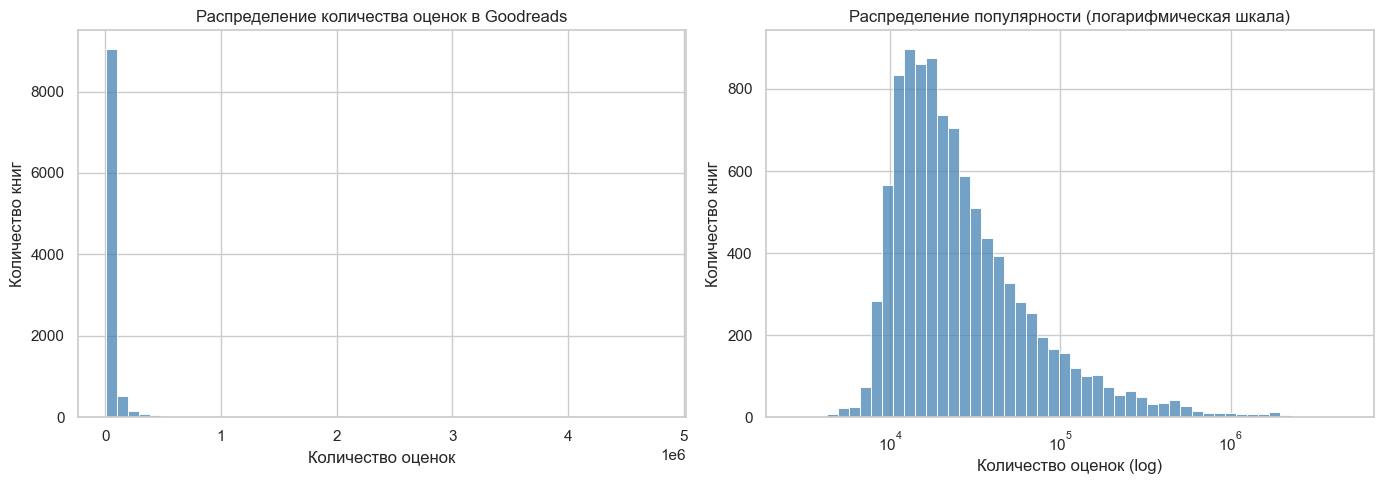

In [22]:
# === Распределение популярности книг в Goodreads ===

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    goodreads_popularity,
    bins=50,
    color="steelblue",
    ax=axes[0],
)

axes[0].set_title("Распределение количества оценок в Goodreads")
axes[0].set_xlabel("Количество оценок")
axes[0].set_ylabel("Количество книг")

# Логарифмическая шкала позволяет лучше увидеть менее популярные книги
sns.histplot(
    goodreads_popularity,
    bins=50,
    log_scale=(True, False),
    color="steelblue",
    ax=axes[1],
)

axes[1].set_title("Распределение популярности (логарифмическая шкала)")
axes[1].set_xlabel("Количество оценок (log)")
axes[1].set_ylabel("Количество книг")

plt.tight_layout()
plt.show()

### Выводы по популярности книг

По результатам анализа популярности книг установлено:

1. В таблице `ratings.csv` представлены оценки для всех 10 000 книг.
Среднее количество оценок на книгу составляет 98,18, медианное - 100.

2. Максимальное количество оценок на книгу равно 100.
Это указывает на ограничение числа оценок при формировании выборки.
Поэтому распределение взаимодействий в `ratings.csv` не отражает реальную популярность произведений.

3. На 20% наиболее популярных книг приходится 20,37% оценок из `ratings.csv`.
Такое распределение близко к равномерному
и не демонстрирует выраженного эффекта длинного хвоста.

4. Дополнительный анализ `books.ratings_count` показал существенно более неравномерное распределение.
Медианное количество оценок составляет около 21 тысячи, среднее около 54 тысяч, а максимальное превышает 4,78 млн.

5. Распределение популярности Goodreads имеет выраженную правостороннюю асимметрию:
большинство книг получают относительно небольшое количество оценок,
тогда как отдельные популярные произведения значительно больше.

6. В данных Goodreads наблюдается эффект длинного хвоста.
При этом его выраженность нельзя корректно оценивать только по `ratings.csv`
из-за ограничения количества взаимодействий на книгу.

**Итог:**

Популярность книг существенно различается,
однако используемая выборка взаимодействий частично скрывает эту особенность.
При построении Popularity-модели и сравнении алгоритмов
необходимо учитывать ограничения исходных данных.

Для корректной offline-оценки моделей статистику пользовательских взаимодействий
будем рассчитывать только на тренировочной выборке.

## 1.6. Анализ пользовательских тегов

Исследуем теги, которыми пользователи Goodreads отмечают книги.

Для анализа используются две таблицы:

- `tags.csv` -> справочник тегов с их названиями
- `book_tags.csv` -> связи между книгами и тегами с количеством применений (`count`)

Необходимо:

- объединить таблицы по идентификатору тега
- определить наиболее часто используемые теги
- изучить распространенность тегов среди книг
- оценить пригодность тегов для построения
  контентной рекомендательной модели

При анализе будем различать количество применений тега и количество книг, которым он присвоен.

In [23]:
# === Объединение тегов и связей книг с тегами ===

book_tags_with_names = book_tags.merge(
    tags,
    on="tag_id",
    how="left",
    validate="many_to_one",
)

print(f"Размер исходной таблицы book_tags: {book_tags.shape}")
print(f"Размер объединенной таблицы: {book_tags_with_names.shape}")

# Проверяем, что все идентификаторы тегов найдены в справочнике
missing_tag_names = book_tags_with_names["tag_name"].isna().sum()

print(f"Количество записей без названия тега: {missing_tag_names}")

display(book_tags_with_names.head(10))

Размер исходной таблицы book_tags: (999912, 3)
Размер объединенной таблицы: (999912, 4)
Количество записей без названия тега: 0


,goodreads_book_id,tag_id,count,tag_name
0,1,30574,167697,to-read
1,1,11305,37174,fantasy
2,1,11557,34173,favorites
3,1,8717,12986,currently-reading
4,1,33114,12716,young-adult
5,1,11743,9954,fiction
6,1,14017,7169,harry-potter
7,1,5207,6221,books-i-own
8,1,22743,4974,owned
9,1,32989,4364,ya


In [24]:
# === Топ-20 тегов по количеству применений ===

top_tags = (
    book_tags_with_names.groupby("tag_name")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
    .reset_index(name="Количество применений")
)

display(top_tags)

,tag_name,Количество применений
0,to-read,140718761
1,currently-reading,7507958
2,favorites,4503173
3,fiction,3688819
4,fantasy,3548157
5,young-adult,1848306
6,classics,1756920
7,books-i-own,1317235
8,romance,1231926
9,owned,1224279


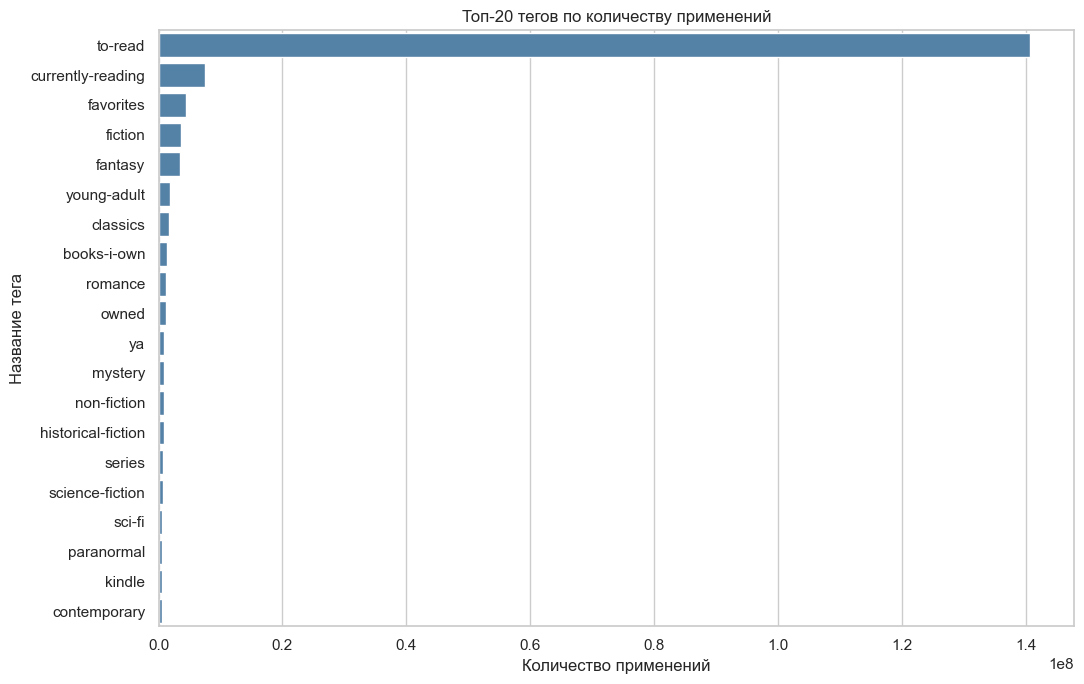

In [25]:
# === Визуализация топ-20 наиболее часто используемых тегов ===

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_tags,
    x="Количество применений",
    y="tag_name",
    color="steelblue",
)

plt.title("Топ-20 тегов по количеству применений")
plt.xlabel("Количество применений")
plt.ylabel("Название тега")
plt.tight_layout()
plt.show()

In [26]:
# === Топ-20 тегов по количеству уникальных книг ===

tag_book_counts = (
    book_tags_with_names.groupby("tag_name")["goodreads_book_id"]
    .nunique()
    .sort_values(ascending=False)
)

top_tags_by_books = (
    tag_book_counts.head(20)
    .reset_index(name="Количество книг")
)

display(top_tags_by_books)

,tag_name,Количество книг
0,to-read,9983
1,favorites,9881
2,owned,9857
3,books-i-own,9799
4,currently-reading,9776
5,library,9415
6,owned-books,9221
7,fiction,9097
8,to-buy,8692
9,kindle,8316


In [27]:
# === Статистика количества уникальных тегов на книгу ===

tags_per_book = (
    book_tags_with_names.groupby("goodreads_book_id")["tag_id"]
    .nunique()
)

print(f"Количество книг с тегами: {len(tags_per_book)}")
print(f"Среднее количество тегов: {tags_per_book.mean():.2f}")
print(f"Медианное количество тегов: {tags_per_book.median():.2f}")
print(f"Минимальное количество тегов: {tags_per_book.min()}")
print(f"Максимальное количество тегов: {tags_per_book.max()}")

display(
    tags_per_book.describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

Количество книг с тегами: 10000
Среднее количество тегов: 99.99
Медианное количество тегов: 100.00
Минимальное количество тегов: 56
Максимальное количество тегов: 100


count    10000.000000
mean        99.990400
std          0.586295
min         56.000000
25%        100.000000
50%        100.000000
75%        100.000000
90%        100.000000
95%        100.000000
99%        100.000000
max        100.000000
Name: tag_id, dtype: float64

### Выводы по анализу пользовательских тегов

По результатам анализа пользовательских тегов установлено:

1. Все записи таблицы `book_tags.csv` успешно объединены со справочником `tags.csv`.
Пропущенных названий тегов не обнаружено.

2. Наиболее часто используемым тегом является `to-read` (более 140 млн применений).
Среди популярных тегов также встречаются `currently-reading`, `favorites`, `fiction`, `fantasy` и `young-adult`.

3. Значительная часть распространенных тегов описывает не содержание книги,
а действия пользователей или организацию личных библиотек.
Такие теги могут быть малоинформативны для контентных рекомендаций.

4. Тег `to-read` присутствует у 9 983 книг из 10 000.
Такие распространенные теги практически не позволяют различать произведения по содержанию.

5. Для всех 10 000 книг доступны пользовательские теги.
Среднее количество уникальных тегов составляет 99,99, а медианное 100.

6. Максимальное количество тегов на книгу равно 100,
что указывает на ограничение числа сохраненных тегов при формировании датасета.

**Итог:**

Пользовательские теги могут использоваться для построения Content-Based рекомендаций,
поскольку содержат информацию о жанрах и тематике книг.

Перед применением TF-IDF потребуется исключить наиболее очевидные служебные теги
и сформировать текстовое представление книг на основе названий и информативных тегов.

Окончательные правила обработки тегов определим на этапе построения контентной модели.

## 1.7. Основные проблемы данных

Рассмотрим основные особенности датасета,
которые могут влиять на качество рекомендательных моделей:

- разреженность матрицы пользователь–книга (sparsity)
- смещение популярности (popularity bias)
- холодный старт пользователей и книг (cold start)

Для оценки разреженности рассчитаем количество возможных взаимодействий между пользователями
и книгами и сравним его с количеством фактически наблюдаемых уникальных пар.

Для этого не будем строить полную матрицу взаимодействий.
Рассчитаем ее размерность и плотность.

In [28]:
# === Оценка разреженности матрицы пользователь - книга ===

users_count = ratings["user_id"].nunique()
books_count = ratings["book_id"].nunique()

# Каждая ячейка матрицы соответствует возможной паре пользователь - книга
possible_interactions = users_count * books_count

# Повторяющиеся оценки одной книги пользователем считаем одним взаимодействием
observed_interactions = ratings[
    ["user_id", "book_id"]
].drop_duplicates().shape[0]

density = observed_interactions / possible_interactions * 100
sparsity = 100 - density

print(f"Количество пользователей: {users_count}")
print(f"Количество книг: {books_count}")
print(f"Размерность матрицы: {users_count} x {books_count}")
print(f"Количество возможных взаимодействий: {possible_interactions:,}")
print(f"Количество наблюдаемых взаимодействий: {observed_interactions:,}")
print(f"Плотность матрицы: {density:.4f}%")
print(f"Разреженность матрицы: {sparsity:.4f}%")

Количество пользователей: 53424
Количество книг: 10000
Размерность матрицы: 53424 × 10000
Количество возможных взаимодействий: 534,240,000
Количество наблюдаемых взаимодействий: 979,478
Плотность матрицы: 0.1833%
Разреженность матрицы: 99.8167%


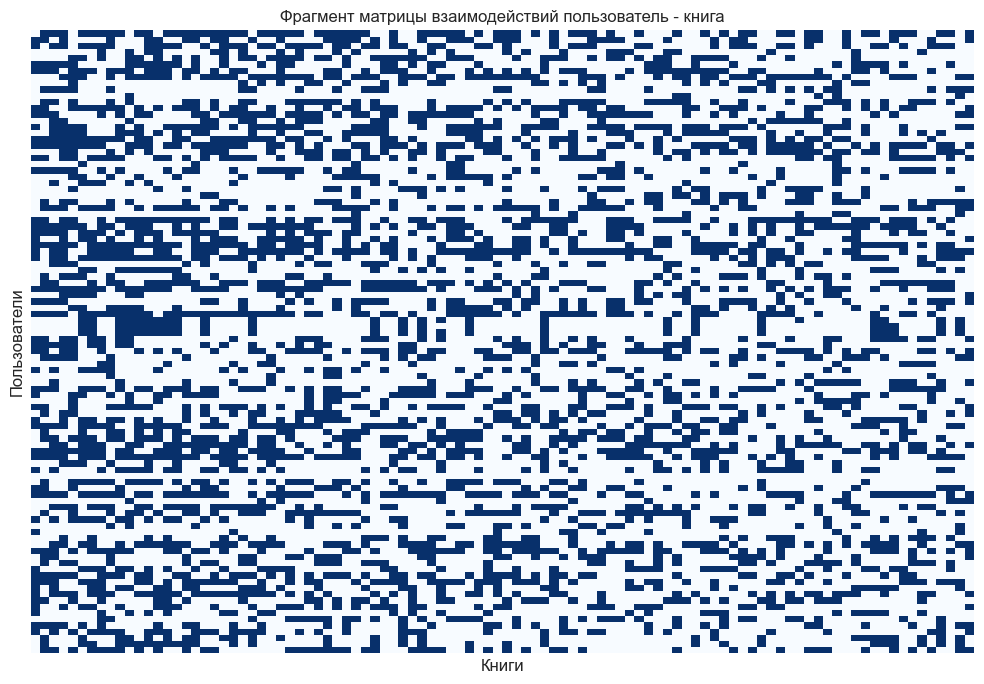

In [29]:
# === Визуализация фрагмента матрицы пользователь - книга ===

sample_users = user_activity.nlargest(100).index

sample_ratings = ratings[
    ratings["user_id"].isin(sample_users)
]

sample_books = (
    sample_ratings.groupby("book_id")
    .size()
    .nlargest(100)
    .index
)

sample_interactions = (
    sample_ratings[
        sample_ratings["book_id"].isin(sample_books)
    ][["user_id", "book_id"]]
    .drop_duplicates()
)

# Формируем бинарную матрицу:
# 1 -> оценка существует
# 0 -> отсутствует
interaction_matrix = (
    sample_interactions.assign(interaction=1)
    .pivot(
        index="user_id",
        columns="book_id",
        values="interaction",
    )
    .reindex(
        index=sample_users,
        columns=sample_books,
    )
    .fillna(0)
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    interaction_matrix,
    cmap="Blues",
    cbar=False,
    xticklabels=False,
    yticklabels=False,
)

plt.title("Фрагмент матрицы взаимодействий пользователь - книга")
plt.xlabel("Книги")
plt.ylabel("Пользователи")
plt.tight_layout()
plt.show()

### Выводы по основным проблемам данных

По результатам проведенного анализа выявлены следующие особенности датасета.

**1. Разреженность матрицы взаимодействий (sparsity)**

- Матрица пользователь - книга имеет размерность 53 424 x 10 000.
- Из 534 240 000 возможных взаимодействий наблюдаются только 979 478 уникальных пар.
- Плотность матрицы составляет 0,1833%, разреженность 99,8167%.

Высокая разреженность затрудняет поиск пользователей и книг с общими взаимодействиями,
что особенно важно для коллаборативной фильтрации.

Отсутствие оценки не означает отрицательное отношение пользователя к книге.

**2. Смещение популярности (popularity bias)**

- В таблице `ratings.csv` количество оценок на книгу ограничено 100 записями,
  поэтому распределение близко к равномерному.
- Дополнительный анализ `books.ratings_count` показал
  выраженную неравномерность популярности произведений.
- Наиболее популярные книги имеют значительно больше оценок,
  чем большинство остальных.

Это создает предпосылки для смещения рекомендаций в сторону популярных книг.
Однако фактическое смещение выдачи можно будет оценить только после построения моделей.

**3. Холодный старт (cold start)**

- Более половины пользователей (56,93%) оставили не более 10 оценок.
- Ограниченная история взаимодействий затрудняет определение индивидуальных предпочтений.
- Пользователи без оценок отсутствуют в `ratings.csv`,
  поэтому оценить их количество невозможно.
- Для всех 10 000 книг доступны метаданные и пользовательские теги,
  которые могут использоваться для рекомендаций при отсутствии достаточной
  истории взаимодействий.

**Итог:**

Основными ограничениями датасета являются высокая разреженность матрицы взаимодействий,
небольшая история оценок у значительной части пользователей и особенности формирования выборки.

Эти ограничения необходимо учитывать при построении и сравнении рекомендательных моделей.

Для пользователей с недостаточной историей взаимодействий можно использовать рекомендации популярных книг,
а для новых книг с доступными метаданными - Content-Based подход.

## 1.8. Итоговые выводы по этапу 1

В ходе разведочного анализа данных Goodbooks-10k изучены исходные таблицы,
распределение пользовательских оценок, активность пользователей,
популярность книг и пользовательские теги.

Основные результаты:

1. **Качество данных.**

В `books.csv` обнаружены пропущенные значения, а в `ratings.csv` и `book_tags.csv` повторяющиеся записи.
Перед обучением моделей потребуется очистка и подготовка данных.

2. **Распределение оценок.**

В датасете преобладают высокие оценки: 66,24% взаимодействий имеют рейтинг 4 или 5.
Средняя оценка составляет 3,86.

3. **Активность пользователей.**

Более половины пользователей (56,93%) оставили не более 10 оценок.
Это ограничивает возможности персонализации для пользователей
с небольшой историей взаимодействий.

4. **Популярность книг.**

В `ratings.csv` количество оценок на книгу ограничено 100 записями.
При этом агрегированные данные Goodreads демонстрируют выраженную
неравномерность популярности и длинный хвост распределения.

5. **Пользовательские теги.**

Для всех 10 000 книг доступны теги, однако среди них присутствует много служебных меток.
Для Content-Based модели потребуется отбор информативных тегов.

6. **Разреженность данных.**

Разреженность матрицы пользователь - книга составляет 99,8167%.
Это может затруднять поиск сходства между книгами и пользователями
при использовании коллаборативной фильтрации.

### План для следующих этапов

На основании результатов EDA планируется:

- обработать повторяющиеся оценки и связи книг с тегами
- построить Popularity baseline как простую модель для сравнения
- использовать названия книг и информативные теги для Content-Based рекомендаций
- применять разреженные матрицы для Item-Based Collaborative Filtering
- использовать SVD для поиска скрытых факторов пользовательских предпочтений
- оценивать модели на единой тестовой выборке, исключая утечку информации из тестовых взаимодействий
- предусмотреть гибридную стратегию для пользователей и книг с недостаточной историей взаимодействий

**Общий вывод:**

Датасет Goodbooks-10k подходит для исследования различных подходов к построению книжных рекомендательных систем.

Разведочный анализ выявил особенности данных, которые необходимо учитывать при подготовке признаков,
обучении моделей и интерпретации метрик качества.